Executing Particle Swarm Optimization on Device: cpu
PARTICLE SWARM OPTIMIZATION RESULTS
Execution Device       : cpu
Number of Particles    : 100
Problem Dimensions     : 10
Search Bounds          : (-5.12, 5.12)
Max Iterations         : 200
----------------------------------------------------------------------
Inertia Weight (w)     : 0.7
Cognitive Constant     : 1.5
Social Constant        : 1.5
----------------------------------------------------------------------
Initial Best Fitness   : 112.634468
Final Best Fitness     : 3.979836e+00

Global Best Position (gbest):
[-9.9492234e-01  9.9484426e-01  3.4465585e-05 -4.6298606e-05
  9.9501377e-01 -1.3391393e-04 -9.9499506e-01 -1.0732336e-05
  4.1851017e-06 -8.5751068e-05]

Total Execution Time   : 0.3132 Seconds


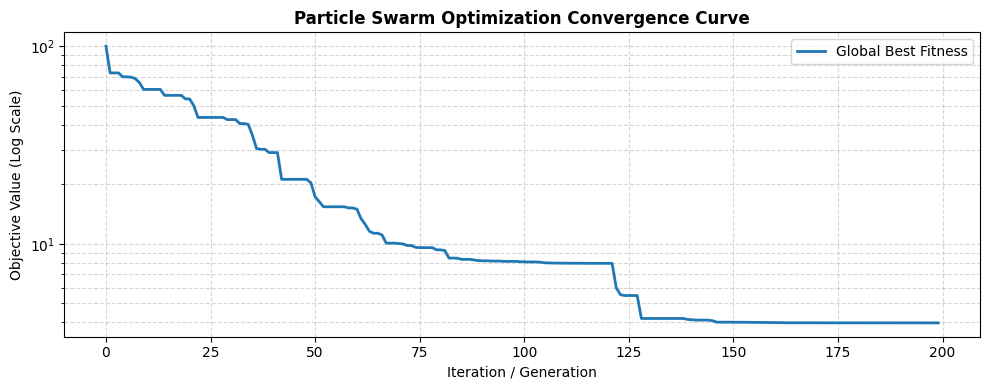

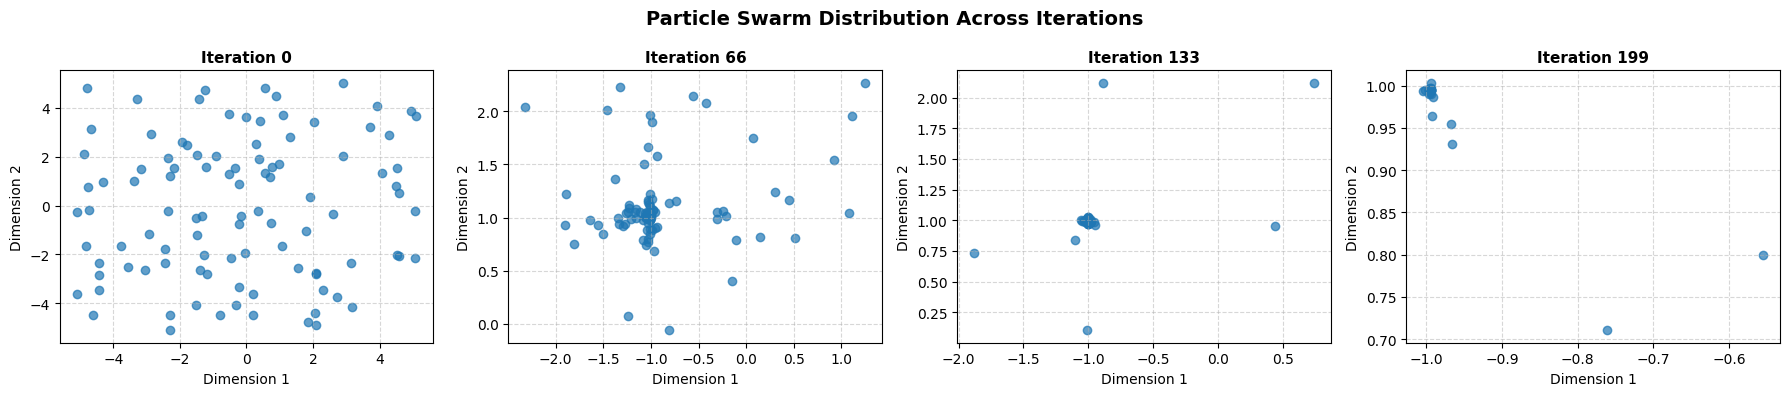

In [1]:
import time
import torch
import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# DEVICE CONFIGURATION
# ==============================================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Executing Particle Swarm Optimization on Device: {device}")

# ==============================================================================
# STEP 1: DEFINE OBJECTIVE FUNCTIONS (Batched Tensor Input)
# ==============================================================================
def sphere_function(x: torch.Tensor) -> torch.Tensor:
    """
    De Jong / Sphere Benchmark:
    f(x) = sum(x_i^2)

    Global Minimum:
    f(0, ..., 0) = 0
    """
    return torch.sum(x**2, dim=-1)


def rastrigin_function(x: torch.Tensor) -> torch.Tensor:
    """
    Rastrigin Benchmark:
    f(x) = 10d + sum(x_i^2 - 10*cos(2*pi*x_i))

    Global Minimum:
    f(0, ..., 0) = 0
    """
    d = x.shape[-1]
    return 10 * d + torch.sum(
        x**2 - 10 * torch.cos(2 * torch.pi * x),
        dim=-1
    )


def rosenbrock_function(x: torch.Tensor) -> torch.Tensor:
    """
    Rosenbrock / Banana Function.

    Global Minimum:
    x = (1, ..., 1)
    f(x) = 0
    """
    return torch.sum(
        100 * (x[..., 1:] - x[..., :-1]**2)**2
        + (1 - x[..., :-1])**2,
        dim=-1
    )


# ==============================================================================
# STEP 2-7: PARTICLE SWARM OPTIMIZATION ENGINE
# ==============================================================================
class ParticleSwarmOptimization:

    def __init__(
        self,
        objective_func,
        dim: int = 10,
        bounds: tuple = (-5.12, 5.12),
        num_particles: int = 100,
        max_iter: int = 200,
        w: float = 0.7,
        c1: float = 1.5,
        c2: float = 1.5
    ):
        self.func = objective_func
        self.dim = dim
        self.bounds = bounds
        self.num_particles = num_particles
        self.max_iter = max_iter

        # PSO Parameters
        self.w = w
        self.c1 = c1
        self.c2 = c2

    def optimize(self):

        start_time = time.time()

        lower, upper = self.bounds

        # ======================================================================
        # STEP 3: INITIALIZE PARTICLE POSITIONS
        # ======================================================================
        X = (
            torch.rand(
                self.num_particles,
                self.dim,
                device=device
            ) * (upper - lower)
            + lower
        )

        # ======================================================================
        # STEP 4: INITIALIZE VELOCITIES
        # ======================================================================
        velocity_range = 0.2 * (upper - lower)

        V = (
            torch.rand(
                self.num_particles,
                self.dim,
                device=device
            ) * (2 * velocity_range)
            - velocity_range
        )

        # ======================================================================
        # STEP 5: INITIAL FITNESS EVALUATION
        # ======================================================================
        fitness = self.func(X)

        initial_best_f = torch.min(fitness).item()

        # ======================================================================
        # PERSONAL BEST INITIALIZATION
        # ======================================================================
        pbest_X = X.clone()
        pbest_F = fitness.clone()

        # ======================================================================
        # GLOBAL BEST INITIALIZATION
        # ======================================================================
        gbest_idx = torch.argmin(pbest_F)

        global_best_f = pbest_F[gbest_idx].item()
        global_best_x = pbest_X[gbest_idx].clone()

        # History for convergence visualization
        history_best_f = []

        # Store particle snapshots for visualization
        particle_snapshots = {}

        snapshot_intervals = [
            0,
            self.max_iter // 3,
            (2 * self.max_iter) // 3,
            self.max_iter - 1
        ]

        # ======================================================================
        # STEP 6: ITERATIVE PARTICLE UPDATES
        # ======================================================================
        for iteration in range(self.max_iter):

            # --------------------------------------------------------------
            # Capture particle positions for visualization
            # --------------------------------------------------------------
            if iteration in snapshot_intervals:

                particle_snapshots[iteration] = (
                    X.detach()
                    .cpu()
                    .numpy()
                    .copy()
                )

            # --------------------------------------------------------------
            # Generate random coefficients
            # --------------------------------------------------------------
            r1 = torch.rand(
                self.num_particles,
                self.dim,
                device=device
            )

            r2 = torch.rand(
                self.num_particles,
                self.dim,
                device=device
            )

            # --------------------------------------------------------------
            # VELOCITY UPDATE
            #
            # v(t+1) =
            # w*v(t)
            # + c1*r1*(pbest-x)
            # + c2*r2*(gbest-x)
            # --------------------------------------------------------------
            V = (
                self.w * V
                + self.c1 * r1 * (pbest_X - X)
                + self.c2 * r2 * (global_best_x - X)
            )

            # --------------------------------------------------------------
            # Limit velocity
            # --------------------------------------------------------------
            V = torch.clamp(
                V,
                -velocity_range,
                velocity_range
            )

            # --------------------------------------------------------------
            # POSITION UPDATE
            #
            # x(t+1) = x(t) + v(t+1)
            # --------------------------------------------------------------
            X = X + V

            # Keep particles inside search space
            X = torch.clamp(
                X,
                lower,
                upper
            )

            # --------------------------------------------------------------
            # EVALUATE NEW PARTICLE FITNESS
            # --------------------------------------------------------------
            fitness = self.func(X)

            # --------------------------------------------------------------
            # UPDATE PERSONAL BEST
            # --------------------------------------------------------------
            improved_mask = fitness < pbest_F

            pbest_X = torch.where(
                improved_mask.unsqueeze(-1),
                X,
                pbest_X
            )

            pbest_F = torch.where(
                improved_mask,
                fitness,
                pbest_F
            )

            # --------------------------------------------------------------
            # UPDATE GLOBAL BEST
            # --------------------------------------------------------------
            current_best_f, current_best_idx = torch.min(
                pbest_F,
                dim=0
            )

            if current_best_f.item() < global_best_f:

                global_best_f = current_best_f.item()

                global_best_x = (
                    pbest_X[current_best_idx]
                    .clone()
                )

            # --------------------------------------------------------------
            # STORE GLOBAL BEST HISTORY
            # --------------------------------------------------------------
            history_best_f.append(global_best_f)

        # ======================================================================
        # FINAL SNAPSHOT
        # ======================================================================
        particle_snapshots[self.max_iter - 1] = (
            X.detach()
            .cpu()
            .numpy()
            .copy()
        )

        elapsed_time = time.time() - start_time

        # ======================================================================
        # STEP 7: OUTPUT METRICS & RESULTS
        # ======================================================================
        print("=" * 70)
        print("PARTICLE SWARM OPTIMIZATION RESULTS")
        print("=" * 70)

        print(f"Execution Device       : {device}")
        print(f"Number of Particles    : {self.num_particles}")
        print(f"Problem Dimensions     : {self.dim}")
        print(f"Search Bounds          : {self.bounds}")
        print(f"Max Iterations         : {self.max_iter}")

        print("-" * 70)

        print(f"Inertia Weight (w)     : {self.w}")
        print(f"Cognitive Constant     : {self.c1}")
        print(f"Social Constant        : {self.c2}")

        print("-" * 70)

        print(f"Initial Best Fitness   : {initial_best_f:.6f}")
        print(f"Final Best Fitness     : {global_best_f:.6e}")

        print("\nGlobal Best Position (gbest):")
        print(global_best_x.cpu().numpy())

        print(f"\nTotal Execution Time   : {elapsed_time:.4f} Seconds")

        print("=" * 70)

        return history_best_f, particle_snapshots


# ==============================================================================
# EXECUTION & VISUALIZATION PIPELINE
# ==============================================================================
if __name__ == "__main__":

    # Choose Objective Function:
    # sphere_function
    # rastrigin_function
    # rosenbrock_function

    target_func = rastrigin_function

    bounds = (-5.12, 5.12)

    max_iterations = 200

    # ======================================================================
    # CREATE PSO MODEL
    # ======================================================================
    pso = ParticleSwarmOptimization(
        objective_func=target_func,
        dim=10,
        bounds=bounds,
        num_particles=100,
        max_iter=max_iterations,
        w=0.7,
        c1=1.5,
        c2=1.5
    )

    # ======================================================================
    # RUN OPTIMIZATION
    # ======================================================================
    history, particle_snapshots = pso.optimize()

    # ======================================================================
    # 1. PLOT CONVERGENCE HISTORY
    # ======================================================================
    plt.figure(figsize=(10, 4))

    plt.plot(
        history,
        color="#1f77b4",
        linewidth=2,
        label="Global Best Fitness"
    )

    plt.yscale("log")

    plt.title(
        "Particle Swarm Optimization Convergence Curve",
        fontsize=12,
        fontweight="bold"
    )

    plt.xlabel(
        "Iteration / Generation",
        fontsize=10
    )

    plt.ylabel(
        "Objective Value (Log Scale)",
        fontsize=10
    )

    plt.grid(
        True,
        which="both",
        linestyle="--",
        alpha=0.5
    )

    plt.legend()

    plt.tight_layout()

    plt.show()

    # ======================================================================
    # 2. PARTICLE DISTRIBUTION VISUALIZATION
    # ======================================================================
    snapshot_keys = sorted(
        particle_snapshots.keys()
    )

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(18, 4)
    )

    for idx, key in enumerate(snapshot_keys):

        particles = particle_snapshots[key]

        # For visualization, use first two dimensions
        x_values = particles[:, 0]
        y_values = particles[:, 1]

        axes[idx].scatter(
            x_values,
            y_values,
            alpha=0.7
        )

        axes[idx].set_title(
            f"Iteration {key}",
            fontsize=11,
            fontweight="bold"
        )

        axes[idx].set_xlabel(
            "Dimension 1"
        )

        axes[idx].set_ylabel(
            "Dimension 2"
        )

        axes[idx].grid(
            True,
            linestyle="--",
            alpha=0.5
        )

    plt.suptitle(
        "Particle Swarm Distribution Across Iterations",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()

    plt.show()

In [2]:
import torch
import numpy as np

# ============================================================
# DE JONG / SPHERE FUNCTION
# Global minimum: 0 at x = [0, 0, ..., 0]
# ============================================================
def de_jong_function(x: torch.Tensor) -> torch.Tensor:
    return torch.sum(x ** 2, dim=1)


# ============================================================
# RASTRIGIN FUNCTION
# Global minimum: 0 at x = [0, 0, ..., 0]
# ============================================================
def rastrigin_function(x: torch.Tensor) -> torch.Tensor:
    d = x.shape[1]
    return 10 * d + torch.sum(
        x ** 2 - 10 * torch.cos(2 * np.pi * x),
        dim=1
    )


# ============================================================
# BANANA / ROSENBROCK FUNCTION
# Global minimum: 0 at x = [1, 1, ..., 1]
# ============================================================
def banana_function(x: torch.Tensor) -> torch.Tensor:
    return torch.sum(
        100 * (x[:, 1:] - x[:, :-1] ** 2) ** 2
        + (1 - x[:, :-1]) ** 2,
        dim=1
    )


# ============================================================
# TEST
# ============================================================
if __name__ == "__main__":

    x = torch.tensor([
        [0.0, 0.0, 0.0],
        [1.0, 1.0, 1.0],
        [2.0, 2.0, 2.0]
    ])

    print("De Jong Function:")
    print(de_jong_function(x))

    print("\nRastrigin Function:")
    print(rastrigin_function(x))

    print("\nBanana (Rosenbrock) Function:")
    print(banana_function(x))

De Jong Function:
tensor([ 0.,  3., 12.])

Rastrigin Function:
tensor([ 0.,  3., 12.])

Banana (Rosenbrock) Function:
tensor([  2.,   0., 802.])


Executing Particle Swarm Optimization on Device: cpu

De Jong Function
Best Position : [9.2354298e-08 1.3193784e-07]
Best Fitness  : 0.00000000
Execution Time: 0.019141 seconds

Rastrigin Function
Best Position : [-3.5360921e-05  3.5496196e-05]
Best Fitness  : 0.00000000
Execution Time: 0.019522 seconds

Banana Function
Best Position : [1.0005279 1.001053 ]
Best Fitness  : 0.00000028
Execution Time: 0.020720 seconds


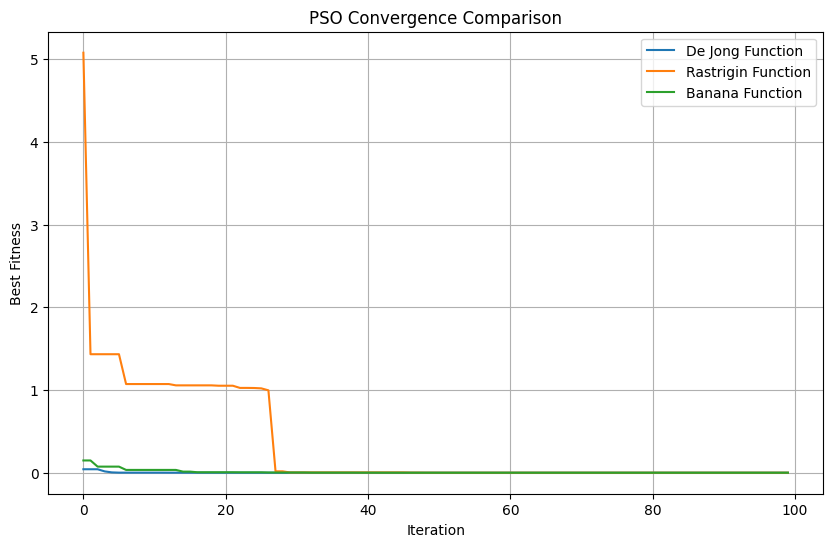

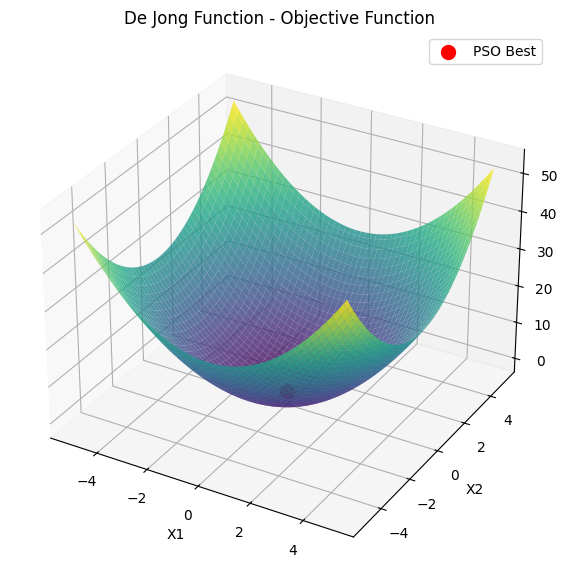

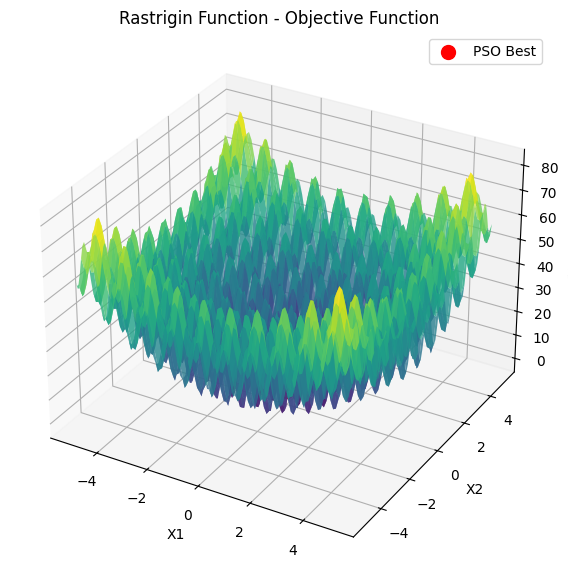

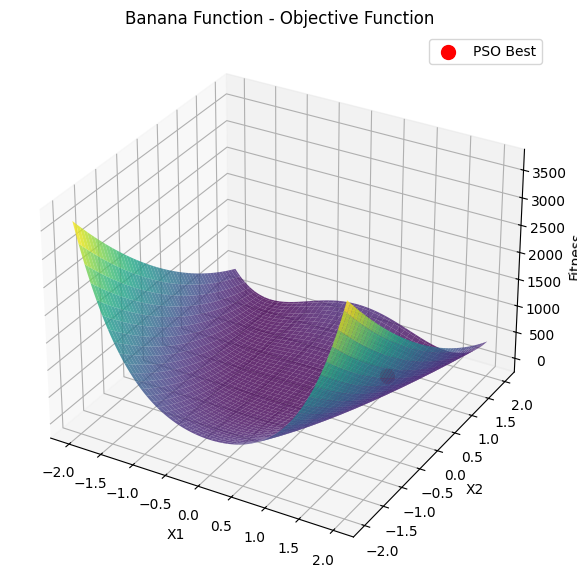

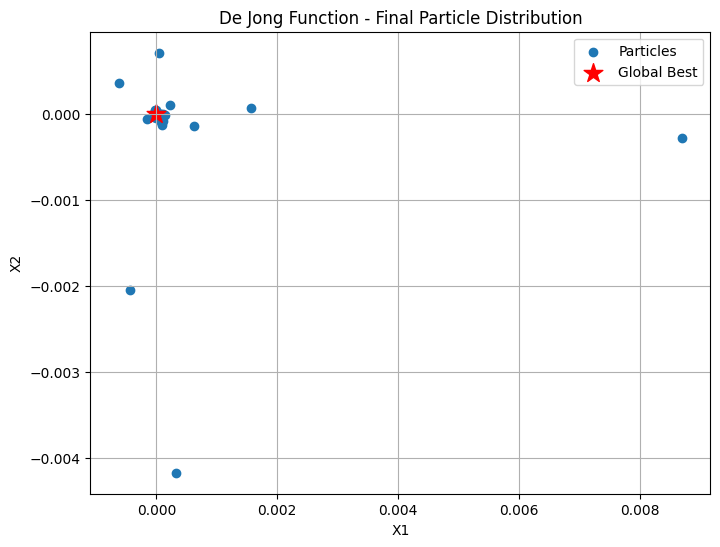

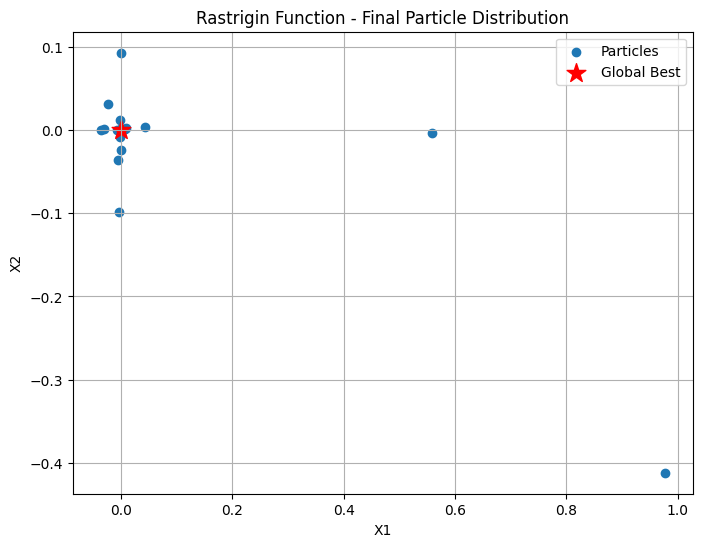

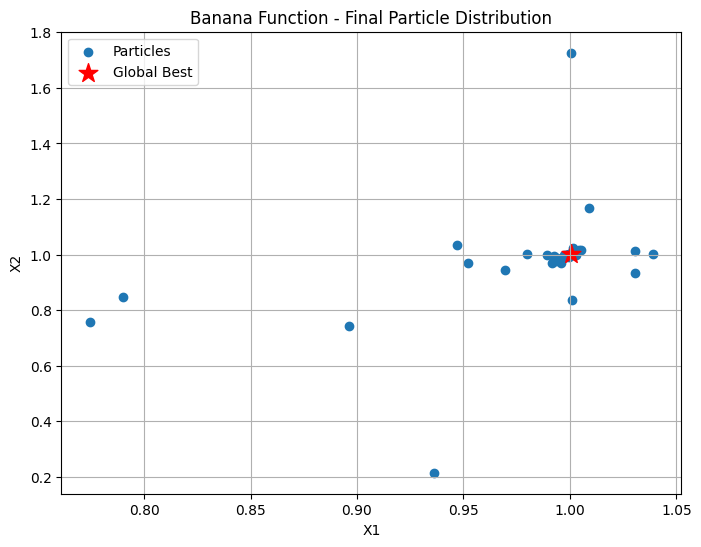


FINAL PSO RESULTS

De Jong Function
Best Position  : [9.2354298e-08 1.3193784e-07]
Best Fitness   : 0.00000000
Execution Time : 0.019141 seconds

Rastrigin Function
Best Position  : [-3.5360921e-05  3.5496196e-05]
Best Fitness   : 0.00000000
Execution Time : 0.019522 seconds

Banana Function
Best Position  : [1.0005279 1.001053 ]
Best Fitness   : 0.00000028
Execution Time : 0.020720 seconds


In [4]:
import time
import torch
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# ==============================================================================
# DEVICE CONFIGURATION
# ==============================================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Executing Particle Swarm Optimization on Device: {device}")


# ==============================================================================
# STEP 1: DEFINE OBJECTIVE FUNCTIONS
# ==============================================================================

def de_jong_function(x):
    return torch.sum(x ** 2, dim=1)


def rastrigin_function(x):
    d = x.shape[1]
    return 10 * d + torch.sum(
        x ** 2 - 10 * torch.cos(2 * np.pi * x),
        dim=1
    )


def banana_function(x):
    return torch.sum(
        100 * (x[:, 1:] - x[:, :-1] ** 2) ** 2
        + (1 - x[:, :-1]) ** 2,
        dim=1
    )


# ==============================================================================
# STEP 2: PARTICLE SWARM OPTIMIZATION
# ==============================================================================

class ParticleSwarmOptimization:

    def __init__(
        self,
        objective_function,
        dim=2,
        bounds=(-5.12, 5.12),
        num_particles=50,
        max_iter=100,
        w=0.7,
        c1=1.5,
        c2=1.5
    ):

        self.objective_function = objective_function
        self.dim = dim
        self.lower = bounds[0]
        self.upper = bounds[1]
        self.num_particles = num_particles
        self.max_iter = max_iter

        self.w = w
        self.c1 = c1
        self.c2 = c2

        # Initialize particle positions
        self.X = (
            torch.rand(
                num_particles,
                dim,
                device=device
            ) * (self.upper - self.lower)
            + self.lower
        )

        # Initialize velocities
        self.V = torch.rand(
            num_particles,
            dim,
            device=device
        ) * 2 - 1

        # Initial fitness
        fitness = self.objective_function(self.X)

        # Personal best
        self.pbest_X = self.X.clone()
        self.pbest_fitness = fitness.clone()

        # Global best
        best_index = torch.argmin(self.pbest_fitness)

        self.gbest_X = self.pbest_X[best_index].clone()
        self.gbest_fitness = self.pbest_fitness[best_index].item()

        # History
        self.history = []
        self.position_history = []

    # --------------------------------------------------------------------------
    # OPTIMIZATION
    # --------------------------------------------------------------------------

    def optimize(self):

        start_time = time.time()

        for iteration in range(self.max_iter):

            # Random coefficients
            r1 = torch.rand(
                self.num_particles,
                self.dim,
                device=device
            )

            r2 = torch.rand(
                self.num_particles,
                self.dim,
                device=device
            )

            # Velocity update
            self.V = (
                self.w * self.V
                + self.c1 * r1 * (self.pbest_X - self.X)
                + self.c2 * r2 * (self.gbest_X - self.X)
            )

            # Position update
            self.X = self.X + self.V

            # Keep particles inside search space
            self.X = torch.clamp(
                self.X,
                self.lower,
                self.upper
            )

            # Evaluate particles
            fitness = self.objective_function(self.X)

            # Update personal best
            improved = fitness < self.pbest_fitness

            self.pbest_X[improved] = self.X[improved]
            self.pbest_fitness[improved] = fitness[improved]

            # Update global best
            best_index = torch.argmin(self.pbest_fitness)

            current_best = self.pbest_fitness[best_index].item()

            if current_best < self.gbest_fitness:
                self.gbest_fitness = current_best
                self.gbest_X = self.pbest_X[best_index].clone()

            # Store history
            self.history.append(self.gbest_fitness)
            self.position_history.append(
                self.X.detach().cpu().numpy().copy()
            )

        execution_time = time.time() - start_time

        return (
            self.gbest_X.detach().cpu().numpy(),
            self.gbest_fitness,
            execution_time
        )


# ==============================================================================
# STEP 3: RUN PSO FOR EACH FUNCTION
# ==============================================================================

functions = {
    "De Jong Function": {
        "function": de_jong_function,
        "bounds": (-5.12, 5.12)
    },

    "Rastrigin Function": {
        "function": rastrigin_function,
        "bounds": (-5.12, 5.12)
    },

    "Banana Function": {
        "function": banana_function,
        "bounds": (-2.0, 2.0)
    }
}


results = {}


for name, settings in functions.items():

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    pso = ParticleSwarmOptimization(
        objective_function=settings["function"],
        dim=2,
        bounds=settings["bounds"],
        num_particles=50,
        max_iter=100,
        w=0.7,
        c1=1.5,
        c2=1.5
    )

    best_position, best_fitness, execution_time = pso.optimize()

    results[name] = {
        "pso": pso,
        "best_position": best_position,
        "best_fitness": best_fitness,
        "execution_time": execution_time
    }

    print(f"Best Position : {best_position}")
    print(f"Best Fitness  : {best_fitness:.8f}")
    print(f"Execution Time: {execution_time:.6f} seconds")


# ==============================================================================
# STEP 4: CONVERGENCE GRAPHS
# ==============================================================================

plt.figure(figsize=(10, 6))

for name, result in results.items():

    plt.plot(
        result["pso"].history,
        label=name
    )

plt.xlabel("Iteration")
plt.ylabel("Best Fitness")
plt.title("PSO Convergence Comparison")
plt.legend()
plt.grid(True)
plt.show()


# ==============================================================================
# STEP 5: OBJECTIVE FUNCTION SURFACES
# ==============================================================================

for name, settings in functions.items():

    lower, upper = settings["bounds"]

    x = np.linspace(lower, upper, 100)
    y = np.linspace(lower, upper, 100)

    X, Y = np.meshgrid(x, y)

    points = torch.tensor(
        np.column_stack(
            [X.ravel(), Y.ravel()]
        ),
        dtype=torch.float32,
        device=device
    )

    Z = settings["function"](points)

    Z = Z.detach().cpu().numpy().reshape(X.shape)

    fig = plt.figure(figsize=(10, 7))

    ax = fig.add_subplot(111, projection="3d")

    ax.plot_surface(
        X,
        Y,
        Z,
        cmap="viridis",
        alpha=0.8
    )

    best_position = results[name]["best_position"]

    best_point = torch.tensor(
        best_position.reshape(1, 2),
        dtype=torch.float32,
        device=device
    )

    best_z = settings["function"](best_point)
    best_z = best_z.item()

    ax.scatter(
        best_position[0],
        best_position[1],
        best_z,
        color="red",
        s=100,
        label="PSO Best"
    )

    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_zlabel("Fitness")

    ax.set_title(f"{name} - Objective Function")

    ax.legend()

    plt.show()


# ==============================================================================
# STEP 6: PARTICLE DISTRIBUTION
# ==============================================================================

for name, result in results.items():

    pso = result["pso"]

    positions = pso.position_history[-1]

    plt.figure(figsize=(8, 6))

    plt.scatter(
        positions[:, 0],
        positions[:, 1],
        label="Particles"
    )

    best = result["best_position"]

    plt.scatter(
        best[0],
        best[1],
        color="red",
        marker="*",
        s=200,
        label="Global Best"
    )

    plt.xlabel("X1")
    plt.ylabel("X2")

    plt.title(
        f"{name} - Final Particle Distribution"
    )

    plt.legend()
    plt.grid(True)

    plt.show()


# ==============================================================================
# STEP 7: FINAL SUMMARY
# ==============================================================================

print("\n" + "=" * 70)
print("FINAL PSO RESULTS")
print("=" * 70)

for name, result in results.items():

    print(f"\n{name}")
    print(f"Best Position  : {result['best_position']}")
    print(f"Best Fitness   : {result['best_fitness']:.8f}")
    print(f"Execution Time : {result['execution_time']:.6f} seconds")